### Modes near the unit circle: `im_cc3m_2x4k_e20`

A mode on the unit circle (`|λ| = 1`) keeps its size from block 6 to block 12 and only rotates, by the angle of `λ`. Inside the circle the mode shrinks, outside it grows. Here we take the modes with `0.9 < |λ| < 1.1` and ask what they fire on, whether they behave as `λ` says, and whether they differ from the bulk of modes.

In [1]:
import copy
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
from datasets import load_dataset
from dotenv import load_dotenv
from safetensors.torch import load_file

sys.path.insert(0, "../scripts/tokae")
from train import JordanKoopmanAutoencoder, encode_pairs

load_dotenv("../.env")
torch.set_grad_enabled(False)
torch.manual_seed(0)
torch.set_num_threads(16)
pd.set_option("display.width", 200)

NAME = "im_cc3m_2x4k_e20"
CKPT_DIR = Path("/tmp/claude-1001/-home-dunstan-git-koopmann/0bba89b8-c8c4-41c4-a0d8-5b331c6750fd/scratchpad/ckpt_live")
NEAR = (0.9, 1.1)

BLUE, ORANGE, MUTED, INK = "#2a78d6", "#eb6834", "#898781", "#52514e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": "#e8e7e3",
        "grid.linewidth": 0.6,
        "legend.frameon": False,
    }
)

/tmp/claude-1001/-home-dunstan-git-koopmann/0bba89b8-c8c4-41c4-a0d8-5b331c6750fd/scratchpad/venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
root = Path(os.getenv("DATASETS_CACHE"))
stats = torch.load(CKPT_DIR / f"{NAME}_stats.pt")
mean, std = stats["mean"].expand(2, -1), stats["std"].expand(2, -1)
val = torch.load(root / "imagenet" / "clip_cls_patch_std_ViT-B-32_val_blocks_5_11.pt")
val_x, val_y = (val["states"].float() - mean) / std, val["labels"]
images = load_dataset("ILSVRC/imagenet-1k", split="validation", cache_dir=os.getenv("DATASETS_CACHE"))
class_names = open_clip.IMAGENET_CLASSNAMES

kae = JordanKoopmanAutoencoder(
    top_k=256,
    shared_modes=stats.get("shared_modes", False),
    in_features=val_x.shape[-1],
    latent_features=2049,
    hidden_config=stats.get("hidden_config", [2048]),
    bias=True,
    batchnorm=False,
    nonlinearity="leaky_relu",
)
kae.load_state_dict(load_file(CKPT_DIR / f"{NAME}.safetensors"))
kae.eval()
eigenvalues = torch.cat([kae.real_eigenvalue.to(torch.cfloat), torch.complex(kae.block_real, kae.block_imag)])

clip, _, _ = open_clip.create_model_and_transforms("ViT-B-32", pretrained="openai", force_quick_gelu=True, cache_dir=f"{os.getenv('HF_HOME')}/open_clip")
clip.eval()
head = torch.load(Path(os.getenv("WEIGHTS_CACHE")) / "tokae" / "zero_shot_head_ViT-B-32.pt")
width = clip.visual.ln_post.normalized_shape[0]


def embed(states):
    cls = states[..., :width] * std[1, :width] + mean[1, :width]
    out = clip.visual.ln_post(cls) @ clip.visual.proj
    return out / out.norm(dim=-1, keepdim=True)


def classify(states):
    return (embed(states) @ head).argmax(dim=-1)


def predict(model, start):
    return torch.cat([model.decode(model.koopman_forward(model.encode(batch), 1)) for batch in start.split(5_000)])


def dampen(mode, alpha):
    edited = copy.deepcopy(kae)
    if mode == 0:
        edited.real_eigenvalue.mul_(alpha)
    else:
        edited.block_real[mode - 1].mul_(alpha)
        edited.block_imag[mode - 1].mul_(alpha)
    return edited


# shape: [images, 2, latent], then each mode as a complex number at both ends (mode 0 is real)
phi = torch.cat([encode_pairs(kae, batch) for batch in val_x.split(5_000)])
z = torch.cat([phi[..., :1].to(torch.cfloat), torch.view_as_complex(phi[..., 1:].unflatten(-1, (-1, 2)).contiguous())], dim=-1)
kept = z[:, 0] != 0
usage = kept.double().mean(dim=0)
energy_share = z[:, 1].abs().pow(2).sum(dim=0) / z[:, 1].abs().pow(2).sum()
true_embeddings = embed(val_x[:, 1])
near = (eigenvalues.abs() > NEAR[0]) & (eigenvalues.abs() < NEAR[1])
print(f"{int(near.sum())} of {len(eigenvalues)} modes have {NEAR[0]} < |λ| < {NEAR[1]}; median |λ| of all modes {eigenvalues.abs().median():.2f}")

/home/dunstan/git/koopmann/koopmann/models/autoencoder.py:48: UserWarning: The latent dimension 2049 should probably be larger than the input dimension 2304!
  warnings.warn(


21 of 1025 modes have 0.9 < |λ| < 1.1; median |λ| of all modes 0.47


##### Every mode, by |λ|

For each mode kept on at least 0.5% of images: how often it is kept, how coherent its top 16 images are (mean cosine of their CLIP embeddings), how well `λ·z₆` predicts `z₁₂` on the images that keep it (R²), and the measured gain `|z₁₂| / |z₆|` (median). Modes near the circle are orange.

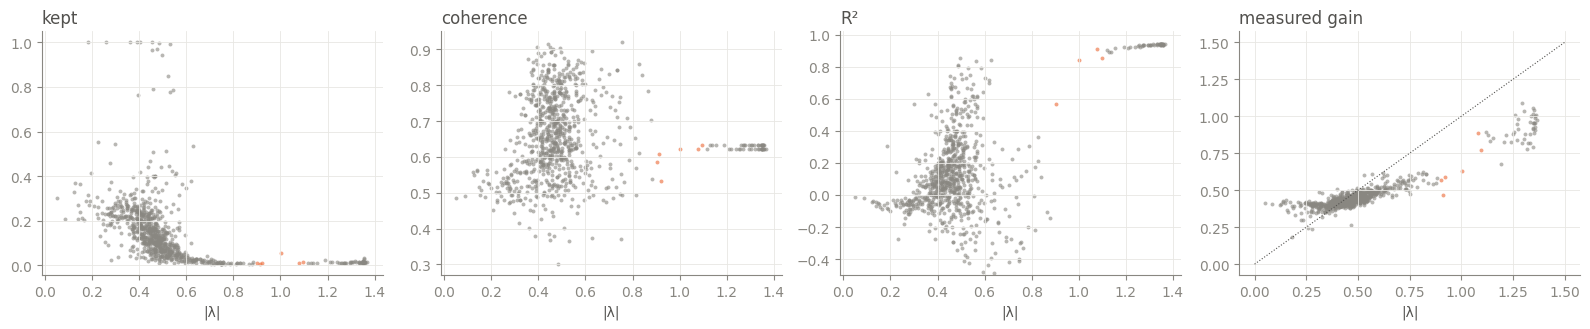

kept        energy share        coherence           R²        measured gain       
           count median        count median     count median count median         count median
|λ|                                                                                           
(0.0, 0.3]    60  0.239           60   0.00        60  0.526    60 -0.056            60  0.400
(0.3, 0.5]   483  0.163          483   0.00       483  0.665   483  0.093           483  0.425
(0.5, 0.7]   204  0.058          204   0.00       204  0.663   204  0.101           204  0.471
(0.7, 0.9]    35  0.011           35   0.00        35  0.654    35 -0.144            35  0.556
(0.9, 1.1]     6  0.010            6   0.00         6  0.614     6  0.702             6  0.608
(1.1, 2.0]    43  0.013           43   0.01        43  0.633    43  0.937            43  0.914

In [3]:
def coherence(indices):
    similarity = true_embeddings[indices] @ true_embeddings[indices].T
    n = len(indices)
    return ((similarity.sum() - n) / (n * (n - 1))).item()


rows = []
for mode in (usage >= 0.005).nonzero()[:, 0].tolist():
    on = kept[:, mode]
    z6, z12 = z[on, 0, mode], z[on, 1, mode]
    top = z[:, 0, mode].abs().topk(16).indices
    rows.append(
        {
            "mode": mode,
            "|λ|": eigenvalues[mode].abs().item(),
            "angle (degrees)": np.degrees(np.angle(eigenvalues[mode].item())),
            "kept": usage[mode].item(),
            "energy share": energy_share[mode].item(),
            "coherence": coherence(top),
            "classes in top 16": len(set(val_y[top].tolist())),
            "measured gain": (z12.abs() / z6.abs()).median().item(),
            "R²": 1 - ((z12 - eigenvalues[mode] * z6).abs().pow(2).sum() / (z12 - z12.mean()).abs().pow(2).sum()).item(),
        }
    )
modes = pd.DataFrame(rows).set_index("mode")
modes["near circle"] = (modes["|λ|"] > NEAR[0]) & (modes["|λ|"] < NEAR[1])

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, column in zip(axes, ["kept", "coherence", "R²", "measured gain"]):
    for flag, color in [(False, MUTED), (True, ORANGE)]:
        part = modes[modes["near circle"] == flag]
        ax.scatter(part["|λ|"], part[column], s=8, color=color, alpha=0.6, lw=0)
    if column == "measured gain":
        ax.plot([0, 1.5], [0, 1.5], color=INK, lw=0.8, ls=":")
    if column == "R²":
        ax.set_ylim(-0.5, 1.02)
    ax.set_xlabel("|λ|")
    ax.set_title(column, loc="left", color=INK)
fig.tight_layout()
plt.show()

modes.groupby(pd.cut(modes["|λ|"], [0, 0.3, 0.5, 0.7, 0.9, 1.1, 2]), observed=True)[["kept", "energy share", "coherence", "R²", "measured gain"]].agg(["count", "median"]).round(3)

##### The modes near the circle

Sorted by how often they are kept. Removing a mode means setting its eigenvalue to 0; we count the images that keep it whose zero-shot answer goes from wrong to right (fixed) or right to wrong (broken).

In [4]:
table = modes[modes["near circle"]].sort_values("kept", ascending=False).copy()
for mode in table.index:
    on = kept[:, mode]
    before = classify(predict(kae, val_x[on, 0])) == val_y[on]
    after = classify(predict(dampen(mode, 0.0), val_x[on, 0])) == val_y[on]
    table.loc[mode, "removing: fixed"] = int((~before & after).sum())
    table.loc[mode, "removing: broken"] = int((before & ~after).sum())
    table.loc[mode, "top classes"] = ", ".join(class_names[c][:16] for c in pd.Series(val_y[z[:, 0, mode].abs().topk(16).indices].tolist()).value_counts().index[:3])
table.drop(columns="near circle").round(3)

,|λ|,angle (degrees),kept,energy share,coherence,classes in top 16,measured gain,R²,removing: fixed,removing: broken,top classes
mode,,,,,,,,,,,
436,1.003,-3.270,0.054,0.001,0.621,15,0.629,0.839,31.0,34.0,"envelope, knee pad, spatula"
508,1.097,0.962,0.013,0.000,0.633,16,0.773,0.856,1.0,4.0,"spatula, knee pad, remote control"
535,1.079,3.278,0.010,0.001,0.621,15,0.888,0.911,3.0,4.0,"envelope, remote control, spatula"
217,0.902,0.384,0.010,0.000,0.585,14,0.569,0.566,2.0,5.0,"tick, Granny Smith app, pan flute"
640,0.920,10.418,0.009,0.000,0.533,11,0.587,-0.868,2.0,0.0,"whiskey jug, coffee mug, tea cup"
203,0.912,-9.826,0.006,0.000,0.608,13,0.469,-1.413,2.0,1.0,"photocopier, filing cabinet, thatched roof"


The 8 validation images where each mode near the circle is most active (by coefficient size at block 6).

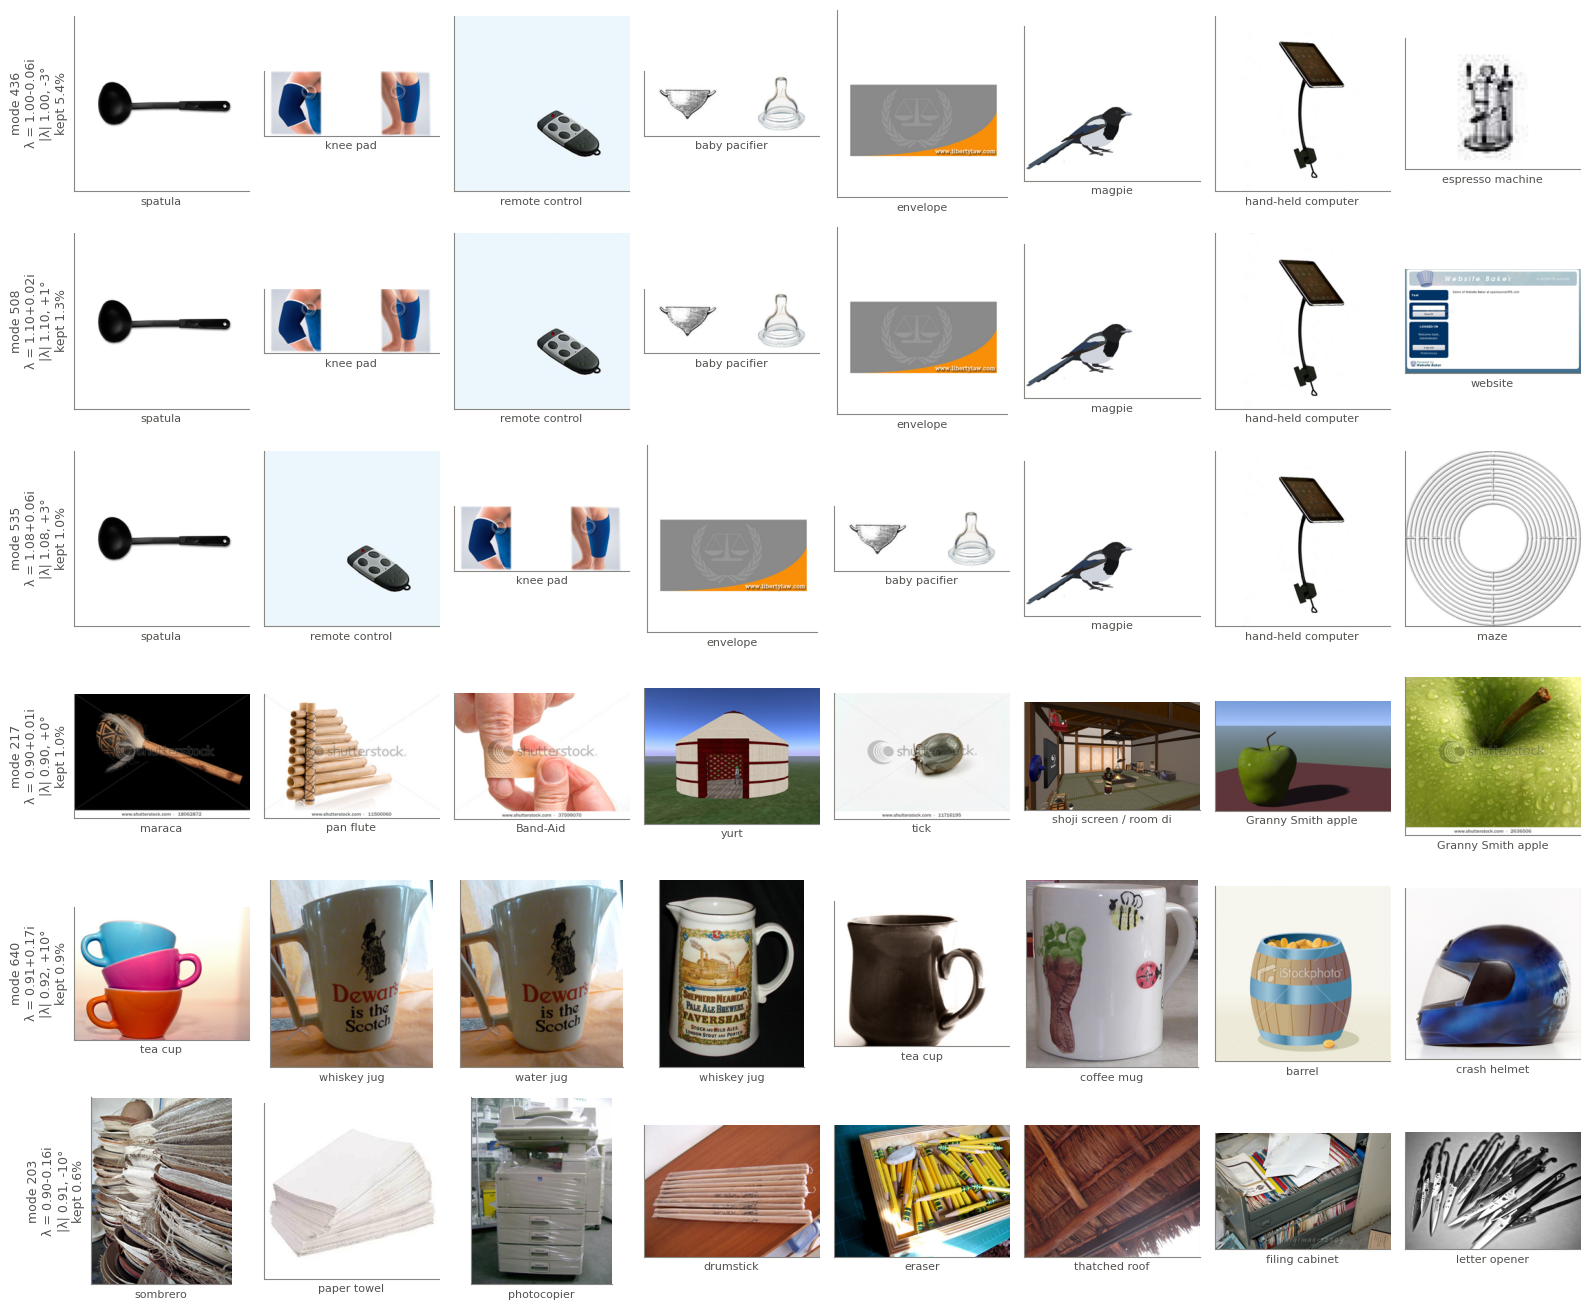

In [5]:
shown = table.index.tolist()
fig, axes = plt.subplots(len(shown), 8, figsize=(16, 2.2 * len(shown)), squeeze=False)
for row, mode in zip(axes, shown):
    for ax, index in zip(row, z[:, 0, mode].abs().topk(8).indices.tolist()):
        image = images[index]["image"].convert("RGB")
        image.thumbnail((256, 256))
        ax.imshow(np.asarray(image))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        ax.set_xlabel(class_names[val_y[index]][:22], fontsize=8, color=INK)
    lam = eigenvalues[mode]
    row[0].set_ylabel(
        f"mode {mode}\nλ = {lam.real:.2f}{lam.imag:+.2f}i\n|λ| {lam.abs():.2f}, {np.degrees(np.angle(lam.item())):+.0f}°\nkept {usage[mode]:.1%}",
        fontsize=9,
        color=INK,
    )
fig.tight_layout()
plt.show()